# 검증 틀 + 피처 실험

- **검증 틀**: train 날짜 4개(월·화·수·토)를 하나씩 검증으로 빼는 **날짜별 4-fold**. 모든 실험을 같은 방식으로 채점함.
- **피처 실험**: `전처리_계획.md`의 피처를 하나씩 추가하면서 검증 MAE 변화를 기록함.
- 결과는 표로 보이고 `../experiments/results.csv`에도 쌓임 (발표의 실험 기록용).

> 커널은 **bis (Python 3.12)**. 데이터는 `baseline_lightgbm.ipynb` 1-1 셀로 미리 받아 둘 것.
> 지금은 `PHASE = 'final'` (대회 데이터). 연습 데이터로 돌리려면 `'practice'`로 바꿈.

**최종 제출 파일 만들기:** `PHASE = 'final'`로 위에서부터 끝까지 실행 → **20번 섹션이 최종 제출 파일 `../submissions/final_E58_sunday_practice.csv`를 만듦** (대회 public 24.309, 지금 최고)
- 그 전 버전: 19번 E56 (24.555), 18번 E46 (24.577), 17번 E41 (24.610), 16번 E35 (24.808, `N_SEEDS = 1`) / E36 (`N_SEEDS = 5`)
- 20번은 연습 데이터(연습 train + 정답 있는 연습 test)를 학습에 추가함. 연습 데이터가 `../data/practice/`에 있어야 함
- 전체 실행 약 7분 (대회 데이터). 기존 제출 파일과 완전히 같은 파일이 나오는 것 확인함 (11/24)

## 0. 설정과 데이터 불러오기

In [1]:
import os, time
from pathlib import Path
import numpy as np
import pandas as pd
import lightgbm as lgb

PHASE = 'final'             # 연습용: 'practice' / 대회: 'final'
RUN_EXPERIMENTS = False     # True: E0~E32 실험을 전부 다시 돌림 (1시간 반 이상) / False: 건너뛰고 기록된 결과만 보여 줌
DATA = Path('../data') / PHASE
LOG = Path('../experiments/results.csv')

train = pd.read_parquet(DATA / 'train.parquet')
test = pd.read_parquet(DATA / 'test.parquet')
print('train', train.shape, '| test', test.shape)
print('train 날짜:', sorted(train.date.unique()))
print('test  날짜:', sorted(test.date.unique()))

train (109891, 24) | test (79942, 24)
train 날짜: ['2024-09-23', '2024-09-24', '2024-09-25', '2024-09-28']
test  날짜: ['2024-09-26', '2024-09-27', '2024-09-29']


## 1. 검증 틀

**fold 나누기**: train 날짜 하나를 검증으로, 나머지 3일을 학습으로 씀.

| 점수 | 뜻 |
|---|---|
| `월`,`화`,`수`,`토` | 그 날짜를 검증으로 뺐을 때 MAE |
| `평일` | 월·화·수 평균 → 목·금 성능 예상 |
| `토` | 주말 성능 → 일요일 성능 예상 (학습에 주말이 없어 실제보다 어려움) |
| **`예상`** | `평일×0.72 + 토×0.28`. 평가 행 비율(목·금 72%, 일 28%)에 맞춘 값. **실험 비교는 이 값으로 함** |

**누수 방지**: 구간 평균 같은 집계 피처는 `make_X(fit, apply)` 안에서 **학습 날짜(fit)로만** 계산함.

In [2]:
DAY = {0: '월', 1: '화', 2: '수', 3: '목', 4: '금', 5: '토', 6: '일'}
DATES = sorted(train.date.unique())

def mae(y, p):
    return float(np.abs(np.asarray(y) - np.asarray(p)).mean())

def summarize(fold_mae):
    """fold별 MAE(dict: 요일→MAE) → 평일 평균, 토, 예상 점수 추가."""
    wd = [v for k, v in fold_mae.items() if k in ('월', '화', '수', '목', '금')]
    we = [v for k, v in fold_mae.items() if k in ('토', '일')]
    out = dict(fold_mae)
    out['평일'] = float(np.mean(wd))
    out['토'] = float(np.mean(we))
    out['예상'] = out['평일'] * 0.72 + out['토'] * 0.28
    return out

def run_cv(predict_fn):
    """predict_fn(fit_df, val_df) → val 예측값. 날짜별 4-fold로 채점함."""
    scores = {}
    for d in DATES:
        fit, val = train[train.date != d], train[train.date == d]
        p = predict_fn(fit, val)
        scores[DAY[pd.Timestamp(d).day_of_week]] = mae(val.tt_sec, p)
    return summarize(scores)

RESULTS = []
def record(name, desc, scores, sec):
    """실험 결과를 표(RESULTS)와 CSV(LOG)에 기록함."""
    row = {'실험': name, '설명': desc, **{k: round(v, 3) for k, v in scores.items()}, '초': round(sec, 1)}
    RESULTS.append(row)
    LOG.parent.mkdir(exist_ok=True)
    pd.DataFrame([{'시각': time.strftime('%Y-%m-%d %H:%M'), 'phase': PHASE, **row}]).to_csv(
        LOG, mode='a', header=not LOG.exists(), index=False)
    print(f"{name:28s} 예상 {row['예상']:.3f} | 평일 {row['평일']:.3f} | 토 {row['토']:.3f}  ({row['초']}초)")

def show():
    t = pd.DataFrame(RESULTS).set_index('실험')
    t['변화'] = (t['예상'] - t['예상'].iloc[0]).round(3)
    return t

## 2. 피처 만들기

피처를 묶음 단위로 만들어 두고, 실험마다 어떤 묶음을 쓸지 고름.

| 묶음 | 내용 | 가설 |
|---|---|---|
| `base` | 노트북 베이스라인 피처 (노선, 방향, 좌표, 거리, 시각, 주말, 첨두, 배차간격) | 출발점 |
| `seg` | 구간 ID(`from_stop→to_stop`)를 범주형으로 | 신호·정류장 혼잡 같은 구간 고유 특성이 가장 큼 |
| `time` | 첫차·막차를 분으로, 노선 마지막 구간 여부 | 끝 구간은 회차 대기로 유난히 김 |
| `te` | 구간별 / 구간×시간 **중앙값** (학습 날짜로만 계산) | 같은 구간의 과거 기록이 가장 좋은 힌트 |
| `trip` | 운행 순서 피처 (그날 몇 번째 운행, 운행 안에서 몇 번째 구간) | 운행이 길어질수록 지연이 쌓임 |
| `busy` | 같은 시간대 같은 노선을 달리는 버스 수 | 배차가 많은 시간 = 수요가 많은 시간 |

In [3]:
PEAK = {7, 8, 9, 17, 18, 19}
SEG = ['route_id', 'direction', 'from_stop', 'to_stop']

def hhmm_to_min(x):
    return (x // 100) * 60 + x % 100

def add_static(df):
    """정답 없이 그 행만 보고 만들 수 있는 피처 (fold와 무관)."""
    df = df.copy()
    dow = pd.to_datetime(df.date).dt.day_of_week
    df['is_weekend'] = (dow >= 5).astype(int)
    df['is_peak'] = df.arrive_hour.isin(PEAK).astype(int)
    df['interval'] = np.select([dow == 5, dow == 6], [df.interval_sat, df.interval_sun], default=df.interval_wd)
    df['dlat'] = df.to_lat - df.from_lat
    df['dlon'] = df.to_lon - df.from_lon
    # seg: 구간 ID
    df['seg_id'] = df.from_stop + '_' + df.to_stop
    # time: 첫차·막차 분, 마지막 구간 여부
    df['first_min'] = hhmm_to_min(df.first_time)
    df['last_min'] = hhmm_to_min(df.last_time)
    df['hour_from_first'] = df.arrive_hour * 60 - df.first_min
    last_seq = pd.concat([train, test]).groupby(['route_id', 'direction']).stop_seq.max().rename('last_seq')
    df = df.join(last_seq, on=['route_id', 'direction'])
    df['is_last_seg'] = (df.stop_seq == df.last_seq).astype(int)
    df['seq_from_end'] = df.last_seq - df.stop_seq
    return df

def add_trip(df):
    """운행 단위 피처. 같은 날·차량·노선·방향 안에서 정류장 순번이 다시 작아지면 새 운행으로 봄."""
    df = df.copy()
    key = ['date', 'vehicle_id', 'route_id', 'direction']
    df = df.sort_values(key + ['arrive_hour', 'stop_seq'])
    new_trip = (df.groupby(key).stop_seq.diff().fillna(-1) <= 0)
    df['trip_no'] = new_trip.groupby([df[k] for k in key]).cumsum()          # 그날 그 방향 몇 번째 운행
    trip = key + ['trip_no']
    df['trip_start_seq'] = df.groupby(trip).stop_seq.transform('min')
    df['seq_in_trip'] = df.stop_seq - df.trip_start_seq                      # 운행 안에서 몇 번째 구간
    df['trip_start_hour'] = df.groupby(trip).arrive_hour.transform('min')
    df['hours_in_service'] = df.arrive_hour - df.groupby(['date', 'vehicle_id']).arrive_hour.transform('min')
    return df.sort_index()

def add_busy(df):
    """같은 날·노선·방향·시간대에 기록된 차량 수 (입력만으로 계산)."""
    df = df.copy()
    df['n_bus_hour'] = df.groupby(['date', 'route_id', 'direction', 'arrive_hour']).vehicle_id.transform('nunique')
    return df

TRAIN = add_busy(add_trip(add_static(train)))
TEST = add_busy(add_trip(add_static(test)))
TRAIN[['seg_id', 'is_last_seg', 'trip_no', 'seq_in_trip', 'hours_in_service', 'n_bus_hour']].describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
seg_id,109891,251,DJB8001348_DJB8002156,884,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_last_seg,109891.0,NaN,NaN,NaN,0.02305,0.150063,0.0,0.0,0.0,0.0,1.0
trip_no,109891.0,NaN,NaN,NaN,3.17946,1.638184,1.0,2.0,3.0,4.0,8.0
seq_in_trip,109891.0,NaN,NaN,NaN,17.855229,11.683287,0.0,8.0,17.0,27.0,46.0
hours_in_service,109891.0,NaN,NaN,NaN,8.287367,5.10446,0.0,4.0,8.0,13.0,18.0
n_bus_hour,109891.0,NaN,NaN,NaN,13.345242,4.891786,1.0,10.0,12.0,18.0,26.0


### 구간 통계 피처 (target encoding)

학습 날짜로 구간별 `tt_sec` 중앙값을 계산해서 붙임.

- **검증·평가 행**: 학습 날짜 전체로 계산한 값을 붙임.
- **학습 행 자신**: 자기 날짜를 뺀 나머지 학습 날짜로 계산함. 자기 정답이 섞인 값을 쓰면 모델이 그 피처를 지나치게 믿게 되기 때문임 (평가 때는 그날 정답이 없으니까).
- 기록이 `MIN_N`건 미만인 칸은 결측으로 두고 LightGBM이 알아서 처리함.

In [4]:
TE_KEYS = {
    'te_seg': SEG,
    'te_seg_hour': SEG + ['arrive_hour'],
}
# 구간×주말 중앙값은 뺐음: 토요일 fold는 학습에 주말이 없어 값이 전부 비고, 토 MAE가 36 → 58로 망가졌음
MIN_N = 5

def te_table(src, keys):
    g = src.groupby(keys).tt_sec.agg(['median', 'size'])
    return g['median'].where(g['size'] >= MIN_N)

def add_te(fit, apply):
    """fit(학습 날짜)로 구간 중앙값 → apply에 붙임. fit 자신은 날짜별 out-of-fold로."""
    fit, apply = fit.copy(), apply.copy()
    for name, keys in TE_KEYS.items():
        apply[name] = apply[keys].join(te_table(fit, keys).rename('v'), on=keys)['v'].values
        fit[name] = np.nan
        for d in fit.date.unique():
            m = fit.date == d
            fit.loc[m, name] = fit.loc[m, keys].join(te_table(fit[~m], keys).rename('v'), on=keys)['v'].values
    for df in (fit, apply):
        df['te_seg_speed'] = df.dist_m / df.te_seg                      # 구간 평소 속도(m/s)
    return fit, apply

## 3. 모델과 실험 실행 함수

In [5]:
FEATS = {
    'base': ['route_id', 'route_type', 'direction', 'interval', 'from_lat', 'from_lon', 'to_lat', 'to_lon',
             'dlat', 'dlon', 'stop_seq', 'dist_m', 'arrive_hour', 'is_weekend', 'is_peak'],
    'seg':  ['seg_id'],
    'time': ['first_min', 'last_min', 'hour_from_first', 'is_last_seg', 'seq_from_end'],
    'te':   list(TE_KEYS) + ['te_seg_speed'],
    'trip': ['trip_no', 'seq_in_trip', 'trip_start_hour', 'hours_in_service'],
    'busy': ['n_bus_hour'],
}
CATS = ['route_id', 'seg_id']
CAT_DTYPE = {c: pd.CategoricalDtype(sorted(pd.concat([TRAIN, TEST])[c].unique())) for c in CATS}

PARAMS = dict(objective='regression_l1', learning_rate=0.05, num_leaves=127, min_child_samples=50,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, n_estimators=600,
              random_state=0, verbose=-1)

def to_X(df, feats):
    X = df[feats].copy()
    for c in CATS:
        if c in X:
            X[c] = X[c].astype(CAT_DTYPE[c])
    return X

def lgb_predictor(groups, params=PARAMS, drop_outlier=None):
    """피처 묶음 목록 → run_cv에 넣을 예측 함수."""
    feats = sum((FEATS[g] for g in groups), [])
    def predict(fit_raw, val_raw):
        return _fit_predict(TRAIN.loc[fit_raw.index], TRAIN.loc[val_raw.index], feats, params, drop_outlier)
    return predict

def _fit_predict(fit, apply, feats, params, drop_outlier):
    if any(f in feats for f in FEATS['te']) or drop_outlier:
        fit, apply = add_te(fit, apply)    # te 피처를 쓰거나 이상치 기준(구간 중앙값)이 필요할 때만 계산
    if drop_outlier:                                       # 학습 행 중 구간 중앙값의 N배 넘는 기록 제외
        fit = fit[~(fit.tt_sec > drop_outlier * fit.te_seg)]
    model = lgb.LGBMRegressor(**params).fit(to_X(fit, feats), fit.tt_sec)
    return model.predict(to_X(apply, feats))

def experiment(name, desc, predict_fn):
    t0 = time.time()
    record(name, desc, run_cv(predict_fn), time.time() - t0)

## 4. 실험

**기준선 0**: 모델 없이 "같은 노선·방향·정류장순번·시간대 평균". 교수님 평가 기준인 '개선 점수'의 기준이 되는 값임. 이보다 좋아야 의미가 있음.

In [6]:
k3 = ['route_id', 'direction', 'stop_seq', 'arrive_hour']
def mean_predict(fit, val):
    m3 = fit.groupby(k3).tt_sec.mean().rename('p3')
    m2 = fit.groupby(k3[:3]).tt_sec.mean().rename('p2')
    x = val[k3].join(m3, on=k3).join(m2, on=k3[:3])
    return x.p3.fillna(x.p2).fillna(fit.tt_sec.mean()).values

# 실험 다시 돌리기 (RUN_EXPERIMENTS = True일 때만, 결과는 experiments/results.csv에 기록됨)
if RUN_EXPERIMENTS:
    experiment('E0 평균 예측', '노선·방향·순번·시간대 평균 (모델 없음)', mean_predict)

**피처를 하나씩 추가**. 좋아진 묶음만 다음 실험에 이어서 씀 (나빠진 묶음은 기록만 하고 뺌).

In [7]:
# 실험 다시 돌리기 (RUN_EXPERIMENTS = True일 때만, 결과는 experiments/results.csv에 기록됨)
if RUN_EXPERIMENTS:
    experiment('E1 base', '노트북 베이스라인 피처', lgb_predictor(['base']))
    experiment('E2 +seg', '+ 구간 ID 범주형', lgb_predictor(['base', 'seg']))
    experiment('E3 +time', '+ 첫차·막차, 마지막 구간', lgb_predictor(['base', 'seg', 'time']))
    experiment('E4 +te', 'E3 + 구간 중앙값 (target encoding)', lgb_predictor(['base', 'seg', 'time', 'te']))
    experiment('E5 +trip', 'E3 + 운행 순서 피처', lgb_predictor(['base', 'seg', 'time', 'trip']))
    experiment('E6 +busy', 'E5 + 시간대 운행 버스 수', lgb_predictor(['base', 'seg', 'time', 'trip', 'busy']))

**이상치 실험**: 학습 데이터에서 구간 중앙값의 N배가 넘는 기록을 빼고 학습함 (검증 행은 그대로 채점).

In [8]:
SET = ['base', 'seg', 'time', 'trip']      # E5 설정
# 실험 다시 돌리기 (RUN_EXPERIMENTS = True일 때만, 결과는 experiments/results.csv에 기록됨)
if RUN_EXPERIMENTS:
    experiment('E7 이상치 제외(5배)', 'E5 + 학습에서 구간중앙값 5배 초과 제외', lgb_predictor(SET, drop_outlier=5))
    experiment('E8 이상치 제외(3배)', 'E5 + 학습에서 구간중앙값 3배 초과 제외', lgb_predictor(SET, drop_outlier=3))

**노선별 모델 실험**: 노선마다 성격이 다르니(특히 1번 급행) 노선별로 모델을 따로 학습하면 더 잘 맞을까?
피처는 E5와 같고, 노선별 데이터가 적어서 `min_child_samples`만 50 → 30으로 줄임.

In [9]:
def per_route_predictor(groups, params=PARAMS):
    """노선마다 LightGBM을 따로 학습해서 그 노선 행만 예측함."""
    feats = sum((FEATS[g] for g in groups), [])
    def predict(fit_raw, val_raw):
        fit, val = TRAIN.loc[fit_raw.index], TRAIN.loc[val_raw.index]
        pred = pd.Series(np.nan, index=val.index)
        for r in val.route_id.unique():
            f, v = fit[fit.route_id == r], val[val.route_id == r]
            m = lgb.LGBMRegressor(**params).fit(to_X(f, feats), f.tt_sec)
            pred[v.index] = m.predict(to_X(v, feats))
        return pred.values
    return predict

# 실험 다시 돌리기 (RUN_EXPERIMENTS = True일 때만, 결과는 experiments/results.csv에 기록됨)
if RUN_EXPERIMENTS:
    experiment('E9 노선별 모델', 'E5 피처, 노선마다 모델 따로 (min_child_samples 30)',
               per_route_predictor(SET, {**PARAMS, 'min_child_samples': 30}))

---
# 7. 분석: 노선별 특성과 역 정류장

모델과 상관없이 데이터를 직접 집계한 것. 발표의 "가설과 근거" 자료용.

### 7-1. 노선별 특성 비교 (train)

In [10]:
t = add_static(train)
t['kmh'] = t.dist_m / t.tt_sec * 3.6
t['is_station'] = t.from_name.str.contains('역')
g = t.groupby('route_nm')
route_tbl = pd.DataFrame({
    '유형': g.route_type.first().map({1: '급행', 2: '간선', 3: '지선', 4: '외곽', 5: '마을', 6: '첨단', 7: '광역'}),
    '배차_평일': g.interval_wd.first(), '배차_토': g.interval_sat.first(), '배차_일': g.interval_sun.first(),
    '정류장수': g.apply(lambda x: pd.unique(pd.concat([x.from_stop, x.to_stop])).size),
    '차량수': g.vehicle_id.nunique(),
    '노선길이_km(편도)': g.apply(lambda x: x.drop_duplicates(['direction', 'stop_seq']).dist_m.sum() / 1000 / 2).round(1),
    '평균거리_m': g.dist_m.mean().round(0),
    '평균tt': g.tt_sec.mean().round(1), '중앙tt': g.tt_sec.median(),
    '중앙속도_kmh': g.kmh.median().round(1),
    '역정류장_비율%': (g.is_station.mean() * 100).round(1),
})
pk, we = t.is_peak == 1, t.is_weekend == 1
route_tbl['첨두/비첨두'] = (t[pk].groupby('route_nm').tt_sec.mean() / t[~pk].groupby('route_nm').tt_sec.mean()).round(3)
route_tbl['주말/평일'] = (t[we].groupby('route_nm').tt_sec.mean() / t[~we].groupby('route_nm').tt_sec.mean()).round(3)
route_tbl.T

route_nm,1,102,511,605
유형,급행,간선,간선,간선
배차_평일,8,7,13,11
배차_토,9,9,13,16
배차_일,10,10,13,16
정류장수,43,89,67,78
차량수,21,34,14,20
노선길이_km(편도),15.2,21.1,13.4,18.0
평균거리_m,728.0,480.0,400.0,466.0
평균tt,160.0,108.9,98.5,115.4
중앙tt,140.0,83.0,69.0,93.0


### 7-2. 정류장 수와 이름에 '역'이 들어간 정류장

In [11]:
both = pd.concat([train, test])
stops = pd.concat([both[['from_stop', 'from_name']].set_axis(['id', 'name'], axis=1),
                   both[['to_stop', 'to_name']].set_axis(['id', 'name'], axis=1)]).drop_duplicates()
print('정류장 ID 수:', stops.id.nunique(), '| 정류장 이름 수:', stops.name.nunique())
station_names = sorted(stops[stops.name.str.contains('역')].name.unique())
print(f'이름에 "역" 들어간 정류장 {len(station_names)}개:', station_names)
print(f"전체 기록 중 역 정류장 출발 비율: {both.from_name.str.contains('역').mean() * 100:.1f}%")
both.assign(역정류장=both.from_name.str.contains('역')).groupby('역정류장').tt_sec.agg(['size', 'mean', 'median']).round(1)

정류장 ID 수: 245 | 정류장 이름 수: 161
이름에 "역" 들어간 정류장 21개: ['갈마역', '구암역', '대동역2번출구', '대동역3번출구', '대동역7번출구', '대전역', '대전역/역전시장', '대전역/중앙시장', '대전역동광장', '서대전네거리역2번출구', '서대전네거리역3번출구', '서대전역네거리', '월평역', '유성온천역6번출구', '유성온천역7번출구', '정부청사역', '중구청역', '중앙로역4번출구', '중앙로역6번출구', '현충원역1번출구', '현충원역3번출구']
전체 기록 중 역 정류장 출발 비율: 15.8%


,size,mean,median
역정류장,,,
False,159745,107.3,82.0
True,30088,160.1,131.0


### 7-3. 노선별 검증 MAE: 모델 1개(E5) vs 노선별 모델(E9)

In [12]:
# 노선별 모델 비교 (모델 8개 학습, RUN_EXPERIMENTS = True일 때만)
if RUN_EXPERIMENTS:
    def cv_by_route(predict_fn):
        rows = []
        for d in DATES:
            fit, val = train[train.date != d], train[train.date == d]
            rows.append(val[['route_nm']].assign(err=np.abs(val.tt_sec.values - predict_fn(fit, val))))
        return pd.concat(rows).groupby('route_nm').err.mean()

    cmp = pd.DataFrame({'E5 모델 1개': cv_by_route(lgb_predictor(SET)),
                        'E9 노선별 모델': cv_by_route(per_route_predictor(SET, {**PARAMS, 'min_child_samples': 30}))})
    cmp['차이(E9-E5)'] = cmp['E9 노선별 모델'] - cmp['E5 모델 1개']
    cmp.round(2)

---
# 8. 피처 추가 실험 (E10~)

`노선_특성.md` 분석에서 나온 가설을 피처로 만들어 E5에 **하나씩** 더해 봄. 마지막에 전부 넣은 것(E19)과 좋아진 것만 넣은 것(E20)을 비교함.

| 실험 | 묶음 | 가설 |
|---|---|---|
| E10 | `station` | 이름에 '역'이 들어간 정류장은 승하차가 많아 정차가 길다 |
| E11 | `peak2` (`is_peak` 대체) | 토요일엔 출근 피크가 없고 낮(11~16시)이 느리다 → 첨두를 평일 아침/저녁, 주말 낮으로 나눔 |
| E12 | `wkhour` | 주말과 평일은 시간대 모양이 다르다 → 주말×시간대 조합 |
| E13 | `turn` | 회차 구간(상행 중 종점 출발)은 종점 대기로 길다. 102·511번은 `is_last_seg`로 못 잡음 |
| E14 | `struct` | 노선 안에서의 위치(누적 거리, 진행률)와 구간이 그 노선 평균보다 긴지 |
| E15 | `share` | 여러 노선이 서는 정류장·구간은 붐빈다 (102·605번이 정류장 28개 공유) |
| E16 | `center` | 도심(대전역)에 가까울수록 느리다 (605번이 가장 느림) |
| E17 | `geo` | 구간 진행 방향, 직선거리 대비 실제 거리(돌아가는 정도) |
| E18 | `tolast` | 막차 근처는 빠르다 |

In [13]:
def hav_m(lat1, lon1, lat2, lon2):
    """두 좌표 사이 직선거리(m)."""
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371000 * 2 * np.arcsin(np.sqrt(a))

BOTH = pd.concat([train, test])

# 노선 구조: 상행·하행별 정류장 수, 평균 구간 거리, 순번별 누적 거리
SEQ = BOTH.drop_duplicates(['route_id', 'direction', 'stop_seq'])[['route_id', 'direction', 'stop_seq', 'dist_m']]
SEQ = SEQ.sort_values(['route_id', 'direction', 'stop_seq'])
SEQ['cum_dist'] = SEQ.groupby(['route_id', 'direction']).dist_m.cumsum() - SEQ.dist_m      # 출발 정류장까지 누적
SEQ['route_len'] = SEQ.groupby(['route_id', 'direction']).dist_m.transform('sum')
SEQ['route_n_stops'] = SEQ.groupby(['route_id', 'direction']).stop_seq.transform('size')
SEQ['route_avg_dist'] = SEQ.groupby('route_id').dist_m.transform('mean')
SEQ = SEQ.drop(columns='dist_m')

# 회차 구간: 상행이면서 출발 정류장 이름 = 하행 첫 정류장 이름(종점)인 첫 구간
TERM = BOTH[BOTH.direction == 1].sort_values('stop_seq').groupby('route_id').from_name.first().rename('term_name')
# 같은 이름 정류장이 여러 개일 수 있어서(102번 대전역동광장 2개) 노선마다 처음 나오는 구간 하나만 회차로 봄
_t = BOTH.join(TERM, on='route_id')
TURN_SEQ = _t[(_t.direction == 0) & (_t.from_name == _t.term_name)].groupby('route_id').stop_seq.min().rename('turn_seq')

# 공유: 정류장·구간을 지나는 노선 수
N_ROUTE_STOP = BOTH.groupby('from_stop').route_id.nunique().rename('n_routes_at_stop')
N_ROUTE_SEG = BOTH.assign(s=BOTH.from_stop + '_' + BOTH.to_stop).groupby('s').route_id.nunique().rename('n_routes_on_seg')

# 도심 기준점: 이름에 '대전역'이 들어간 정류장들의 평균 좌표 (데이터 안의 좌표만 사용)
_c = BOTH[BOTH.from_name.str.contains('대전역')]
CENTER = (_c.from_lat.mean(), _c.from_lon.mean())

def add_more(df):
    df = df.copy()
    # station
    df['from_is_station'] = df.from_name.str.contains('역').astype(int)
    df['to_is_station'] = df.to_name.str.contains('역').astype(int)
    # peak2
    wd, we, h = df.is_weekend == 0, df.is_weekend == 1, df.arrive_hour
    df['is_am_peak_wd'] = (wd & h.between(7, 9)).astype(int)
    df['is_pm_peak_wd'] = (wd & h.between(17, 19)).astype(int)
    df['is_midday_we'] = (we & h.between(11, 16)).astype(int)
    # wkhour
    df['wk_hour'] = df.is_weekend * 100 + df.arrive_hour
    # turn
    df = df.join(TURN_SEQ, on='route_id')
    df['is_turn'] = (df.stop_seq == df.turn_seq).astype(int)
    df['turn_interval'] = df.is_turn * df.interval
    df['turn_hour'] = np.where(df.is_turn == 1, df.arrive_hour, -1)
    # struct
    df = df.merge(SEQ, on=['route_id', 'direction', 'stop_seq'], how='left').set_axis(df.index)
    df['progress'] = df.cum_dist / df.route_len
    df['dist_ratio'] = df.dist_m / df.route_avg_dist
    # share
    df = df.join(N_ROUTE_STOP, on='from_stop').join(N_ROUTE_SEG, on='seg_id')
    df['n_bus_stop_hour'] = df.groupby(['date', 'from_stop', 'arrive_hour']).vehicle_id.transform('nunique')
    # center
    df['dist_to_center'] = hav_m(df.from_lat, df.from_lon, *CENTER)
    # geo
    df['heading'] = np.degrees(np.arctan2(df.dlat, df.dlon))
    df['straight_m'] = hav_m(df.from_lat, df.from_lon, df.to_lat, df.to_lon)
    df['detour'] = df.dist_m / df.straight_m.clip(lower=1)
    # tolast
    df['min_to_last'] = df.last_min - df.arrive_hour * 60
    return df

TRAIN, TEST = add_more(TRAIN), add_more(TEST)

# E10 확인: 회차 구간이 노선마다 하나씩 잡히는지
TRAIN[TRAIN.is_turn == 1].groupby(['route_nm', 'stop_seq', 'from_name', 'to_name']).tt_sec.agg(['size', 'median'])

,,,,size,median
route_nm,stop_seq,from_name,to_name,,
1,21,신안동,신안동,385,579.0
102,47,대전역동광장,대전역동광장,432,807.5
511,35,중촌주공2단지,푸르지오아파트,298,700.0
605,37,갈마아파트3단지,갈마아파트3단지,154,483.0


### 8-1. 하나씩 추가 (E10~E18)

In [14]:
FEATS.update({
    'station': ['from_is_station', 'to_is_station'],
    'peak2':   ['is_am_peak_wd', 'is_pm_peak_wd', 'is_midday_we'],
    'wkhour':  ['wk_hour'],
    'turn':    ['is_turn', 'turn_interval', 'turn_hour'],
    'struct':  ['cum_dist', 'progress', 'route_len', 'route_n_stops', 'route_avg_dist', 'dist_ratio'],
    'share':   ['n_routes_at_stop', 'n_routes_on_seg', 'n_bus_stop_hour'],
    'center':  ['dist_to_center'],
    'geo':     ['heading', 'straight_m', 'detour'],
    'tolast':  ['min_to_last'],
})

def feats_of(groups, drop=()):
    return [f for f in sum((FEATS[g] for g in groups), []) if f not in drop]

def lgb_feats(feats, params=PARAMS):
    """피처 이름 목록으로 바로 예측 함수 만들기 (is_peak 빼기 같은 경우용)."""
    def predict(fit_raw, val_raw):
        return _fit_predict(TRAIN.loc[fit_raw.index], TRAIN.loc[val_raw.index], feats, params, None)
    return predict

SET = ['base', 'seg', 'time', 'trip']      # E5
E5_SCORE = 28.870                           # E5 예상 점수 (위 결과표)

# 실험 다시 돌리기 (RUN_EXPERIMENTS = True일 때만, 결과는 experiments/results.csv에 기록됨)
if RUN_EXPERIMENTS:
    experiment('E10 +station', 'E5 + 역 정류장 여부(출발·도착)', lgb_feats(feats_of(SET + ['station'])))
    experiment('E11 peak 수정', 'E5에서 is_peak → 평일 아침·평일 저녁·주말 낮', lgb_feats(feats_of(SET + ['peak2'], drop=['is_peak'])))
    experiment('E12 +wkhour', 'E5 + 주말×시간대 조합', lgb_feats(feats_of(SET + ['wkhour'])))
    experiment('E13 +turn', 'E5 + 회차 구간, 회차×배차, 회차×시간대', lgb_feats(feats_of(SET + ['turn'])))
    experiment('E14 +struct', 'E5 + 누적 거리, 진행률, 노선 길이·정류장 수·평균 거리', lgb_feats(feats_of(SET + ['struct'])))
    experiment('E15 +share', 'E5 + 정류장·구간 지나는 노선 수, 정류장 시간대 버스 수', lgb_feats(feats_of(SET + ['share'])))
    experiment('E16 +center', 'E5 + 대전역까지 거리', lgb_feats(feats_of(SET + ['center'])))
    experiment('E17 +geo', 'E5 + 진행 방향, 직선거리, 돌아가는 정도', lgb_feats(feats_of(SET + ['geo'])))
    experiment('E18 +tolast', 'E5 + 막차까지 남은 시간', lgb_feats(feats_of(SET + ['tolast'])))

### 8-2. 전부 넣기(E19) vs 좋아진 것만(E20)

In [15]:
# 실험 다시 돌리기 (RUN_EXPERIMENTS = True일 때만, 결과는 experiments/results.csv에 기록됨)
if RUN_EXPERIMENTS:
    NEW = ['station', 'peak2', 'wkhour', 'turn', 'struct', 'share', 'center', 'geo', 'tolast']
    experiment('E19 전부', 'E5 + E10~E18 피처 전부 (is_peak 대체)', lgb_feats(feats_of(SET + NEW, drop=['is_peak'])))

    # E20: 하나씩 넣었을 때 E5보다 좋아진 묶음만
    one = {r['실험']: r['예상'] for r in RESULTS}
    names = dict(zip(NEW, ['E10 +station', 'E11 peak 수정', 'E12 +wkhour', 'E13 +turn', 'E14 +struct',
                           'E15 +share', 'E16 +center', 'E17 +geo', 'E18 +tolast']))
    GOOD = [g for g in NEW if one[names[g]] < E5_SCORE]
    print('E5보다 좋아진 묶음:', GOOD)
    drop = ['is_peak'] if 'peak2' in GOOD else []
    experiment('E20 좋은 것만', 'E5 + ' + ', '.join(GOOD), lgb_feats(feats_of(SET + GOOD, drop=drop)))
    t = pd.DataFrame(RESULTS).set_index('실험')
    t['E5 대비'] = (t['예상'] - E5_SCORE).round(3)
    t

---
# 9. 하이퍼파라미터 조정

피처는 E5 그대로, LightGBM 설정만 바꿔 봄. 설정을 **하나씩 차례로** 비교해서 가장 좋은 값으로 고정하고 다음 설정으로 넘어감 (모든 조합을 다 돌리면 400번 넘게 걸려서).

- 채택 기준: 지금 값보다 `예상` 점수가 **0.02초 넘게** 좋아질 때만 바꿈 (seed만 바꿔도 0.01초 흔들리므로)
- 순서: `num_leaves` → `min_child_samples` → `learning_rate`+`n_estimators` → `colsample_bytree` → `reg_lambda`

In [16]:
# 실험 다시 돌리기 (RUN_EXPERIMENTS = True일 때만, 결과는 experiments/results.csv에 기록됨)
if RUN_EXPERIMENTS:
    TUNE = [
        ('num_leaves',        [{'num_leaves': v} for v in (31, 63, 255)]),
        ('min_child_samples', [{'min_child_samples': v} for v in (20, 100, 200)]),
        ('learning_rate',     [{'learning_rate': 0.03, 'n_estimators': 1000}, {'learning_rate': 0.1, 'n_estimators': 300}]),
        ('colsample_bytree',  [{'colsample_bytree': v} for v in (0.5, 1.0)]),
        ('reg_lambda',        [{'reg_lambda': v} for v in (1, 10)]),
    ]
    MIN_GAIN = 0.02
    feats = feats_of(SET)
    best_params = dict(PARAMS)
    best = run_cv(lgb_feats(feats, best_params))
    print(f"시작(E5 설정): 예상 {best['예상']:.3f}")
    tune_log = [{'단계': '시작', '바꾼 것': '-', **{k: round(v, 3) for k, v in best.items()}}]
    for name, options in TUNE:
        tried = []
        for opt in options:
            p = {**best_params, **opt}
            t0 = time.time(); r = run_cv(lgb_feats(feats, p))
            tried.append((r['예상'], opt, r))
            tune_log.append({'단계': name, '바꾼 것': str(opt), **{k: round(v, 3) for k, v in r.items()}, '초': round(time.time() - t0)})
            print(f"  {name:18s} {str(opt):45s} 예상 {r['예상']:.3f} ({r['예상'] - best['예상']:+.3f})  {time.time() - t0:.0f}초", flush=True)
        s, opt, r = min(tried, key=lambda x: x[0])
        if best['예상'] - s > MIN_GAIN:
            best_params, best = {**best_params, **opt}, r
            print(f"→ {name} 채택: {opt}  예상 {best['예상']:.3f}")
        else:
            print(f"→ {name} 그대로 유지")
    changed = {k: v for k, v in best_params.items() if PARAMS.get(k) != v}
    print('최종 바뀐 설정:', changed)
    record('E23 하이퍼파라미터 조정', f'E5 피처, 바꾼 설정 {changed}', best, 0)
    TUNED_PARAMS = best_params
    pd.DataFrame(tune_log)

---
# 10. CatBoost 섞기 (E26, E27)

같은 피처(E5)로 **다른 종류의 모델**(CatBoost)을 학습해서 LightGBM(E23 설정) 예측과 섞음. 모델마다 틀리는 방식이 달라서 평균 내면 실수가 서로 상쇄되는 효과를 기대함.

- E26: CatBoost 혼자
- E27: LightGBM × w + CatBoost × (1 − w). 섞는 비율 w는 **4-fold 검증 예측으로만** 고름 (test는 마지막 확인용)

In [17]:
# 실험 다시 돌리기 (RUN_EXPERIMENTS = True일 때만, 결과는 experiments/results.csv에 기록됨)
if RUN_EXPERIMENTS:
    from catboost import CatBoostRegressor

    LGB_PARAMS = {**PARAMS, 'min_child_samples': 20, 'learning_rate': 0.03, 'n_estimators': 1000}   # E23 설정
    CB_PARAMS = dict(loss_function='MAE', iterations=2000, learning_rate=0.08, depth=8,
                     random_seed=0, verbose=0, thread_count=-1)
    feats = feats_of(SET)
    CB_CATS = [c for c in ['route_id', 'seg_id'] if c in feats]

    def cb_fit_predict(fit, apply):
        m = CatBoostRegressor(**CB_PARAMS, cat_features=CB_CATS)
        m.fit(fit[feats], fit.tt_sec)
        return m.predict(apply[feats])

    def lgb_fit_predict(fit, apply):
        return _fit_predict(fit, apply, feats, LGB_PARAMS, None)

    # 4-fold: 두 모델의 검증 예측(OOF)을 모아 둠
    OOF = pd.DataFrame(index=TRAIN.index, columns=['lgb', 'cb'], dtype=float)
    for d in DATES:
        t0 = time.time()
        fit, val = TRAIN[TRAIN.date != d], TRAIN[TRAIN.date == d]
        OOF.loc[val.index, 'lgb'] = lgb_fit_predict(fit, val)
        OOF.loc[val.index, 'cb'] = cb_fit_predict(fit, val)
        print(f"fold {DAY[pd.Timestamp(d).day_of_week]} 완료 ({time.time() - t0:.0f}초)", flush=True)

    def cv_of(pred):
        s = {DAY[pd.Timestamp(d).day_of_week]: mae(TRAIN.tt_sec[TRAIN.date == d], pred[TRAIN.date == d]) for d in DATES}
        return summarize(s)

    blend = pd.DataFrame([{'w(LightGBM)': w, **cv_of(w * OOF.lgb + (1 - w) * OOF.cb)} for w in np.round(np.arange(0, 1.01, 0.1), 1)])
    print(blend[['w(LightGBM)', '평일', '토', '예상']].round(3).to_string(index=False))
    BEST_W = float(blend.loc[blend['예상'].idxmin(), 'w(LightGBM)'])
    print('가장 좋은 비율: LightGBM', BEST_W, '/ CatBoost', round(1 - BEST_W, 1))
    record('E26 CatBoost', 'E5 피처, CatBoost (MAE, depth 8, lr 0.08, 2000회)', cv_of(OOF.cb), 0)
    record('E27 LGB+CatBoost', f'E23 LightGBM × {BEST_W} + CatBoost × {1 - BEST_W:.1f}', cv_of(BEST_W * OOF.lgb + (1 - BEST_W) * OOF.cb), 0)
    show().tail(3)

In [18]:
# 실험 다시 돌리기 (RUN_EXPERIMENTS = True일 때만, 결과는 experiments/results.csv에 기록됨)
if RUN_EXPERIMENTS:
    # 연습 test 확인 (train 4일 전체로 학습)
    P_TEST = pd.DataFrame({'lgb': lgb_fit_predict(TRAIN, TEST), 'cb': cb_fit_predict(TRAIN, TEST)}, index=TEST.index)
    cands = {'LightGBM (E23)': P_TEST.lgb, 'CatBoost (E26)': P_TEST.cb, '반반': 0.5 * P_TEST.lgb + 0.5 * P_TEST.cb,
             f'섞기 (E27, w={BEST_W})': BEST_W * P_TEST.lgb + (1 - BEST_W) * P_TEST.cb}
    if 'tt_sec' in test.columns:
        import sys; sys.path.append('../src')
        from evaluate import score
        for name, p in cands.items():
            sub = pd.DataFrame({'row_id': TEST.row_id.values, 'tt_sec': np.round(p.values, 1)}).set_index('row_id').loc[test.row_id].reset_index()
            r = score(sub.copy(), test[['row_id', 'tt_sec']], test)
            t = test.assign(p=sub.tt_sec.values)
            day = {DAY[pd.Timestamp(d).day_of_week]: round(mae(x.tt_sec, x.p), 2) for d, x in t.groupby('date')}
            print(f"{name:22s} test MAE {r['MAE']:.3f}  {day}  노선 { {k: round(v, 2) for k, v in r['노선별 MAE'].items()} }")
    p = BEST_W * P_TEST.lgb + (1 - BEST_W) * P_TEST.cb
    sub = pd.DataFrame({'row_id': TEST.row_id.values, 'tt_sec': np.round(p.values, 1)}).set_index('row_id').loc[test.row_id].reset_index()
    sub.to_csv(f'../submissions/{PHASE}_E27_lgb_cb.csv', index=False)

---
# 11. XGBoost까지 섞기 (E28, E29)

10번의 LightGBM·CatBoost 검증 예측(`OOF`)에 XGBoost를 추가해서 세 모델을 섞음.
- E28: XGBoost 혼자
- E29: LightGBM × a + CatBoost × b + XGBoost × c (a + b + c = 1). 비율은 **4-fold 검증 예측으로만** 0.1 단위로 전부 시험해서 고름

In [19]:
# 실험 다시 돌리기 (RUN_EXPERIMENTS = True일 때만, 결과는 experiments/results.csv에 기록됨)
if RUN_EXPERIMENTS:
    from xgboost import XGBRegressor

    XGB_PARAMS = dict(objective='reg:absoluteerror', tree_method='hist', enable_categorical=True, max_cat_to_onehot=1,
                      n_estimators=1000, learning_rate=0.05, max_depth=8, min_child_weight=20,
                      subsample=0.8, colsample_bytree=0.8, random_state=0, n_jobs=-1)

    def xgb_fit_predict(fit, apply):
        m = XGBRegressor(**XGB_PARAMS)
        m.fit(to_X(fit, feats), fit.tt_sec)
        return m.predict(to_X(apply, feats))

    OOF['xgb'] = np.nan
    for d in DATES:
        t0 = time.time()
        fit, val = TRAIN[TRAIN.date != d], TRAIN[TRAIN.date == d]
        OOF.loc[val.index, 'xgb'] = xgb_fit_predict(fit, val)
        print(f"fold {DAY[pd.Timestamp(d).day_of_week]} 완료 ({time.time() - t0:.0f}초)", flush=True)

    # 세 모델 비율: 0.1 단위로 전부 시험 (66가지)
    rows = []
    for a in np.arange(0, 1.01, 0.1):
        for b in np.arange(0, 1.01 - a, 0.1):
            a_, b_ = round(a, 1), round(b, 1); c_ = round(1 - a_ - b_, 1)
            rows.append({'LightGBM': a_, 'CatBoost': b_, 'XGBoost': c_, **cv_of(a_ * OOF.lgb + b_ * OOF.cb + c_ * OOF.xgb)})
    blend3 = pd.DataFrame(rows).sort_values('예상')
    print(blend3[['LightGBM', 'CatBoost', 'XGBoost', '평일', '토', '예상']].head(8).round(3).to_string(index=False))
    W3 = blend3.iloc[0][['LightGBM', 'CatBoost', 'XGBoost']].to_dict()
    print('가장 좋은 비율:', W3)
    record('E28 XGBoost', 'E5 피처, XGBoost (절대오차, depth 8, lr 0.05, 1000개)', cv_of(OOF.xgb), 0)
    record('E29 LGB+CB+XGB', f"LightGBM {W3['LightGBM']} + CatBoost {W3['CatBoost']} + XGBoost {W3['XGBoost']}",
           cv_of(W3['LightGBM'] * OOF.lgb + W3['CatBoost'] * OOF.cb + W3['XGBoost'] * OOF.xgb), 0)
    OOF.to_parquet('../experiments/oof_lgb_cb_xgb.parquet')
    show().tail(2)

In [20]:
# 실험 다시 돌리기 (RUN_EXPERIMENTS = True일 때만, 결과는 experiments/results.csv에 기록됨)
if RUN_EXPERIMENTS:
    # 연습 test 확인
    P_TEST['xgb'] = xgb_fit_predict(TRAIN, TEST)
    p3 = W3['LightGBM'] * P_TEST.lgb + W3['CatBoost'] * P_TEST.cb + W3['XGBoost'] * P_TEST.xgb
    cands = {'LightGBM (E23)': P_TEST.lgb, 'CatBoost (E26)': P_TEST.cb, 'XGBoost (E28)': P_TEST.xgb,
             f'LGB+CB (E27)': BEST_W * P_TEST.lgb + (1 - BEST_W) * P_TEST.cb,
             '세 모델 (E29)': p3, '1/3씩 (참고)': P_TEST[['lgb', 'cb', 'xgb']].mean(1)}
    if 'tt_sec' in test.columns:
        for name, p in cands.items():
            sub = pd.DataFrame({'row_id': TEST.row_id.values, 'tt_sec': np.round(p.values, 1)}).set_index('row_id').loc[test.row_id].reset_index()
            r = score(sub.copy(), test[['row_id', 'tt_sec']], test)
            t = test.assign(p=sub.tt_sec.values)
            day = {DAY[pd.Timestamp(d).day_of_week]: round(mae(x.tt_sec, x.p), 2) for d, x in t.groupby('date')}
            print(f"{name:16s} test MAE {r['MAE']:.3f}  {day}  노선 { {k: round(v, 2) for k, v in r['노선별 MAE'].items()} }")
    sub = pd.DataFrame({'row_id': TEST.row_id.values, 'tt_sec': np.round(p3.values, 1)}).set_index('row_id').loc[test.row_id].reset_index()
    sub.to_csv(f'../submissions/{PHASE}_E29_lgb_cb_xgb.csv', index=False)
    print('저장:', f'../submissions/{PHASE}_E29_lgb_cb_xgb.csv', sub.shape)

---
# 12. 최고 조합 하이퍼파라미터 추가 조정 (E30, E31, E32)

지금 최고 조합(E27: LightGBM 0.9 + CatBoost 0.1)의 두 모델을 각각 더 조정함.
- E30: LightGBM 추가 조정 (E23 설정에서 시작)
- E31: CatBoost 조정 (처음 조정)
- E32: 조정된 두 모델로 섞는 비율 다시 고르기 (4-fold 검증 예측으로만)

방식: 설정을 하나씩 차례로 비교, 0.02초 넘게 좋아질 때만 바꿈.

In [21]:
from catboost import CatBoostRegressor
feats = feats_of(SET)
CB_CATS = ['route_id', 'seg_id']
LGB_BASE = {**PARAMS, 'min_child_samples': 20, 'learning_rate': 0.03, 'n_estimators': 1000}     # E23
CB_BASE = dict(loss_function='MAE', iterations=2000, learning_rate=0.08, depth=8, l2_leaf_reg=3,
               random_seed=0, verbose=0, thread_count=-1)                                        # E26

def lgb_fp(fit, apply, p):
    return _fit_predict(fit, apply, feats, p, None)

def cb_fp(fit, apply, p):
    m = CatBoostRegressor(**p, cat_features=CB_CATS); m.fit(fit[feats], fit.tt_sec)
    return m.predict(apply[feats])

def oof_of(fp, p):
    """4-fold 검증 예측 (행마다 그 날짜를 뺀 모델의 예측)"""
    out = pd.Series(np.nan, index=TRAIN.index)
    for d in DATES:
        fit, val = TRAIN[TRAIN.date != d], TRAIN[TRAIN.date == d]
        out[val.index] = fp(fit, val, p)
    return out

def cv_of(pred):
    return summarize({DAY[pd.Timestamp(d).day_of_week]: mae(TRAIN.tt_sec[TRAIN.date == d], pred[TRAIN.date == d]) for d in DATES})

def tune(name, fp, base, steps, base_oof=None):
    best_p = dict(base)
    best_oof = base_oof if base_oof is not None else oof_of(fp, best_p)
    best = cv_of(best_oof); log = [{'모델': name, '단계': '시작', '바꾼 것': '-', **best}]
    print(f"[{name}] 시작 예상 {best['예상']:.3f}", flush=True)
    for step, options in steps:
        tried = []
        for opt in options:
            t0 = time.time(); o = oof_of(fp, {**best_p, **opt}); r = cv_of(o)
            tried.append((r['예상'], opt, o, r)); log.append({'모델': name, '단계': step, '바꾼 것': str(opt), **r})
            print(f"  {step:18s} {str(opt):48s} 예상 {r['예상']:.3f} ({r['예상'] - best['예상']:+.3f}) {time.time() - t0:.0f}초", flush=True)
        s, opt, o, r = min(tried, key=lambda x: x[0])
        if best['예상'] - s > 0.02:
            best_p, best_oof, best = {**best_p, **opt}, o, r; print(f"  → {step} 채택 {opt}: 예상 {best['예상']:.3f}", flush=True)
        else:
            print(f"  → {step} 그대로", flush=True)
    return best_p, best_oof, best, log

# 실험 다시 돌리기 (RUN_EXPERIMENTS = True일 때만, 결과는 experiments/results.csv에 기록됨)
if RUN_EXPERIMENTS:
    OOF0 = pd.read_parquet('../experiments/oof_lgb_cb_xgb.parquet')     # 11번에서 저장한 E23·E26 검증 예측
    LGB_P, LGB_OOF, LGB_R, log1 = tune('LightGBM', lgb_fp, LGB_BASE, [
        ('min_child_samples', [{'min_child_samples': 10}]),
        ('learning_rate',     [{'learning_rate': 0.02, 'n_estimators': 1500}]),
        ('subsample',         [{'subsample': 0.7}, {'subsample': 0.9}]),
    ], base_oof=OOF0.lgb)
    CB_P, CB_OOF, CB_R, log2 = tune('CatBoost', cb_fp, CB_BASE, [
        ('depth',         [{'depth': 6}, {'depth': 10}]),
        ('learning_rate', [{'learning_rate': 0.05, 'iterations': 3000}, {'learning_rate': 0.12, 'iterations': 1500}]),
        ('l2_leaf_reg',   [{'l2_leaf_reg': 1}, {'l2_leaf_reg': 10}]),
    ], base_oof=OOF0.cb)

    chg = lambda p, b: {k: v for k, v in p.items() if b.get(k) != v}
    record('E30 LightGBM 추가 조정', f'E23에서 바꾼 것 {chg(LGB_P, LGB_BASE)}', LGB_R, 0)
    record('E31 CatBoost 조정', f'E26에서 바꾼 것 {chg(CB_P, CB_BASE)}', CB_R, 0)

    blend = pd.DataFrame([{'w(LightGBM)': w, **cv_of(w * LGB_OOF + (1 - w) * CB_OOF)} for w in np.round(np.arange(0, 1.01, 0.1), 1)])
    print(blend[['w(LightGBM)', '평일', '토', '예상']].round(3).to_string(index=False))
    W = float(blend.loc[blend['예상'].idxmin(), 'w(LightGBM)'])
    record('E32 조정 후 섞기', f'E30 × {W} + E31 × {1 - W:.1f}', cv_of(W * LGB_OOF + (1 - W) * CB_OOF), 0)
    TUNE2_LOG = pd.DataFrame(log1 + log2)
    TUNE2_LOG[['모델', '단계', '바꾼 것', '평일', '토', '예상']].round(3)

In [22]:
# 실험 다시 돌리기 (RUN_EXPERIMENTS = True일 때만, 결과는 experiments/results.csv에 기록됨)
if RUN_EXPERIMENTS:
    # 연습 test 확인
    PT = pd.DataFrame({'lgb': lgb_fp(TRAIN, TEST, LGB_P), 'cb': cb_fp(TRAIN, TEST, CB_P)}, index=TEST.index)
    cands = {'E30 LightGBM': PT.lgb, 'E31 CatBoost': PT.cb, f'E32 섞기 (w={W})': W * PT.lgb + (1 - W) * PT.cb}
    if 'tt_sec' in test.columns:
        import sys; sys.path.append('../src')
        from evaluate import score
        for name, p in cands.items():
            sub = pd.DataFrame({'row_id': TEST.row_id.values, 'tt_sec': np.round(p.values, 1)}).set_index('row_id').loc[test.row_id].reset_index()
            r = score(sub.copy(), test[['row_id', 'tt_sec']], test)
            t = test.assign(p=sub.tt_sec.values)
            day = {DAY[pd.Timestamp(d).day_of_week]: round(mae(x.tt_sec, x.p), 2) for d, x in t.groupby('date')}
            print(f"{name:20s} test MAE {r['MAE']:.3f}  {day}  노선 { {k: round(v, 2) for k, v in r['노선별 MAE'].items()} }")
    p = W * PT.lgb + (1 - W) * PT.cb
    sub = pd.DataFrame({'row_id': TEST.row_id.values, 'tt_sec': np.round(p.values, 1)}).set_index('row_id').loc[test.row_id].reset_index()
    sub.to_csv(f'../submissions/{PHASE}_E32_tuned_blend.csv', index=False)
    print('저장:', f'../submissions/{PHASE}_E32_tuned_blend.csv', sub.shape)

---
# 13. 실험 결과 정리

E0~E32 전체 결과. `RUN_EXPERIMENTS = False`면 `experiments/results.csv`에 기록된 값을 불러와서 보여 줌.
`변화`는 E0(평균 예측) 대비 차이. 음수일수록 좋음. 나빠진 실험도 지우지 않고 기록함.

In [23]:
if RESULTS:                                         # 이번 실행에서 실험을 돌린 경우
    res = show()
else:                                               # 기록된 결과 불러오기 (같은 실험은 마지막 기록만)
    log = pd.read_csv(LOG)
    SHOW_PHASE = PHASE if (log.phase == PHASE).any() else 'practice'   # 대회 기록이 아직 없으면 연습 기록을 보여 줌
    print(f'{SHOW_PHASE} 실험 기록 ({LOG})')
    res = (log.query('phase == @SHOW_PHASE').drop_duplicates('실험', keep='last')
             .set_index('실험')[['설명', '월', '화', '수', '토', '평일', '예상']])
    res['변화'] = (res['예상'] - res['예상'].iloc[0]).round(3)
res

,설명,월,화,수,토,평일,예상,변화
실험,,,,,,,,
E0 평균 예측,노선·방향·순번·시간대 평균 (모델 없음),29.532,28.459,28.714,37.570,28.902,31.329,0.000
E1 base,노트북 베이스라인 피처,26.809,25.989,26.071,36.765,26.290,29.223,-2.106
E2 +seg,+ 구간 ID 범주형,26.621,25.887,25.978,36.130,26.162,28.953,-2.376
E3 +time,"+ 첫차·막차, 마지막 구간",26.571,25.820,25.910,36.188,26.100,28.925,-2.404
E4 +te,E3 + 구간 중앙값 (target encoding),27.172,26.452,26.534,36.421,26.719,29.436,-1.893
E5 +trip,E3 + 운행 순서 피처,26.496,25.689,25.851,36.221,26.012,28.870,-2.459
E6 +busy,E5 + 시간대 운행 버스 수,26.520,25.789,25.859,35.971,26.056,28.832,-2.497
E7 이상치 제외(5배),E5 + 학습에서 구간중앙값 5배 초과 제외,26.510,25.697,25.919,36.210,26.042,28.889,-2.440
E8 이상치 제외(3배),E5 + 학습에서 구간중앙값 3배 초과 제외,26.716,26.004,26.125,36.078,26.282,29.025,-2.304


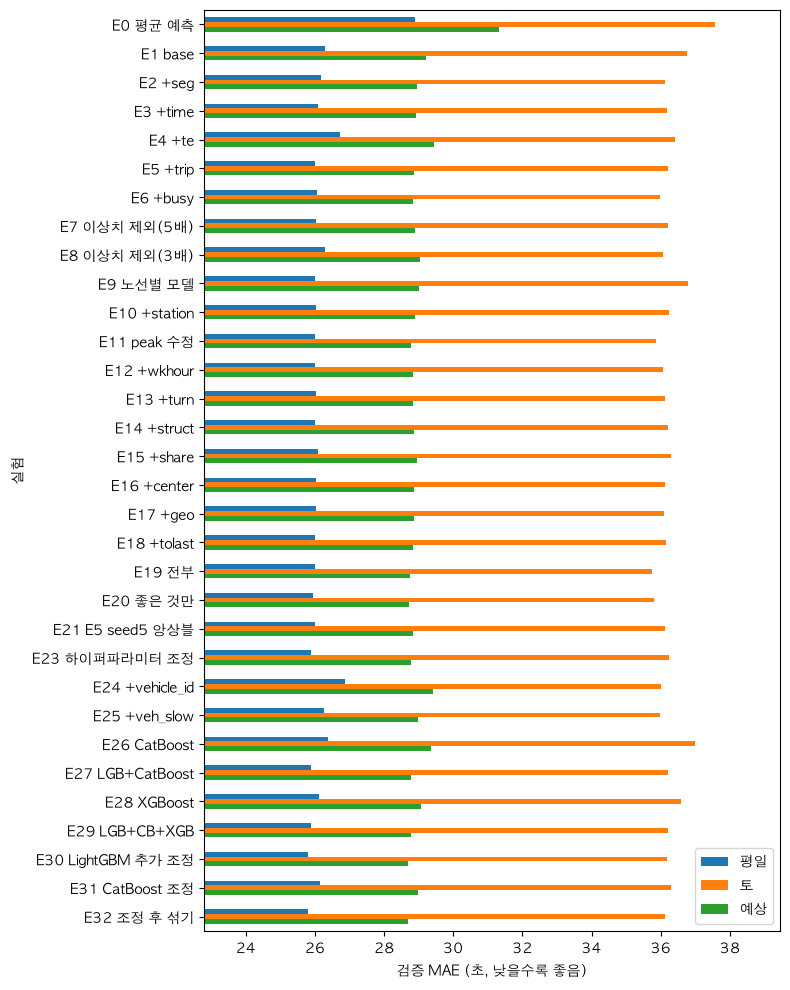

In [24]:
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'AppleGothic'      # 맥 한글 폰트 (윈도우: 'Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False
ax = res[['평일', '토', '예상']].plot.barh(figsize=(8, 10))
ax.invert_yaxis(); ax.set_xlabel('검증 MAE (초, 낮을수록 좋음)'); ax.set_xlim(res[['평일', '토', '예상']].min().min() - 3)
plt.tight_layout(); plt.show()

---
# 14. 최종 모델과 제출 파일

**지금 최고 조합 (E32)**: E5 피처 25개 + LightGBM(E30 설정) × 0.8 + CatBoost(E31 설정) × 0.2
- 4-fold 검증 예상 28.685 / 연습 test 27.473 (교수님 베이스라인 28.05)
- **train 전체**로 두 모델을 다시 학습해서 test를 예측함
- 연습용(`practice`)은 test에 정답이 있으니 채점까지 함 (마지막 확인용, 실험 선택에는 안 씀)
- 대회(`final`)는 `PHASE = 'final'`로 바꾸고 처음부터 실행 → `../submissions/final_E32.csv`를 사이트에 올림
- 대회 데이터에서 비율을 다시 고르려면 `RUN_EXPERIMENTS = True`로 12번을 돌려서 나온 `W`를 아래 `FINAL_W`에 넣음

In [25]:
from catboost import CatBoostRegressor

FINAL_FEATS = feats_of(['base', 'seg', 'time', 'trip'])                          # E5 피처 25개
FINAL_LGB = {**PARAMS, 'min_child_samples': 10, 'learning_rate': 0.02, 'n_estimators': 1500}     # E30
FINAL_CB = dict(loss_function='MAE', iterations=2000, learning_rate=0.08, depth=10, l2_leaf_reg=3,
                random_seed=0, verbose=0, thread_count=-1)                          # E31
FINAL_W = 0.8                                                                      # LightGBM 비율 (E32)

t0 = time.time()
lgb_model = lgb.LGBMRegressor(**FINAL_LGB).fit(to_X(TRAIN, FINAL_FEATS), TRAIN.tt_sec)
p_lgb = lgb_model.predict(to_X(TEST, FINAL_FEATS))
cb_model = CatBoostRegressor(**FINAL_CB, cat_features=['route_id', 'seg_id']).fit(TRAIN[FINAL_FEATS], TRAIN.tt_sec)
p_cb = cb_model.predict(TEST[FINAL_FEATS])
pred = FINAL_W * p_lgb + (1 - FINAL_W) * p_cb
print(f'학습·예측 {time.time() - t0:.0f}초')

sub = pd.DataFrame({'row_id': TEST.row_id.values, 'tt_sec': np.round(pred, 1)})
sub = sub.set_index('row_id').loc[test.row_id].reset_index()      # 원래 test 순서로
os.makedirs('../submissions', exist_ok=True)
path = f'../submissions/{PHASE}_E32.csv'
sub.to_csv(path, index=False)
print(path, sub.shape, '| 결측', int(sub.tt_sec.isna().sum()), '| 중복', int(sub.row_id.duplicated().sum()))

if 'tt_sec' in test.columns:                     # 연습용: 정답이 있으므로 채점
    import sys; sys.path.append('../src')
    from evaluate import score
    r = score(sub.copy(), test[['row_id', 'tt_sec']], test)
    print(f"test MAE {r['MAE']:.3f}  RMSE {r['RMSE']:.3f}  첨두 {r['첨두 MAE']:.3f}  비첨두 {r['비첨두 MAE']:.3f}")
    print('노선별', {k: round(v, 2) for k, v in r['노선별 MAE'].items()})
    t = test.assign(p=sub.tt_sec.values)
    print('날짜별', {DAY[pd.Timestamp(d).day_of_week]: round(mae(g.tt_sec, g.p), 2) for d, g in t.groupby('date')})

학습·예측 67초
../submissions/practice_E32.csv (79942, 2) | 결측 0 | 중복 0
test MAE 27.473  RMSE 55.633  첨두 29.576  비첨두 26.338
노선별 {'1': 33.35, '102': 26.79, '511': 24.99, '605': 26.88}
날짜별 {'목': 25.6, '금': 27.0, '일': 30.49}


---
# 15. 오차 분석: 일요일 (연습 test, 정답이 있을 때만)

연습 test에서 일요일 MAE가 평일보다 3~5초 나쁨. 어떻게 틀리는지 확인.
- 잔차 = 실제 − 예측. 음수면 실제보다 **길게** 예측한 것
- 구간 평소 대비 비율 = 그 행의 통행시간 ÷ 그 구간 전체 중앙값. 요일·시간대별로 얼마나 빠르고 느린지 비교

요일별 잔차·MAE


,행수,잔차중앙값,잔차평균,길게예측비율,MAE
day,,,,,
금,28713,0.29,4.52,49.11,27.00
목,28853,-0.12,3.05,50.32,25.60
일,22376,-3.55,-2.13,58.37,30.49


구간 평소 대비 통행시간 비율 (시간대별 중앙값)


arrive_hour,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
grp,,,,,,,,,,,,,,,,,,,
평일,0.88,0.91,1.02,1.06,1.03,1.01,1.01,1.01,1.02,1.03,1.05,1.07,1.10,1.11,1.02,1.00,0.95,0.88,0.82
토,0.88,0.87,0.90,0.95,0.99,1.02,1.03,1.03,1.02,1.04,1.03,1.04,1.05,1.00,0.99,0.94,0.90,0.83,0.77
일,0.84,0.84,0.87,0.91,0.94,0.97,0.96,0.98,0.99,1.00,0.99,1.00,0.97,0.96,0.95,0.93,0.88,0.81,0.80


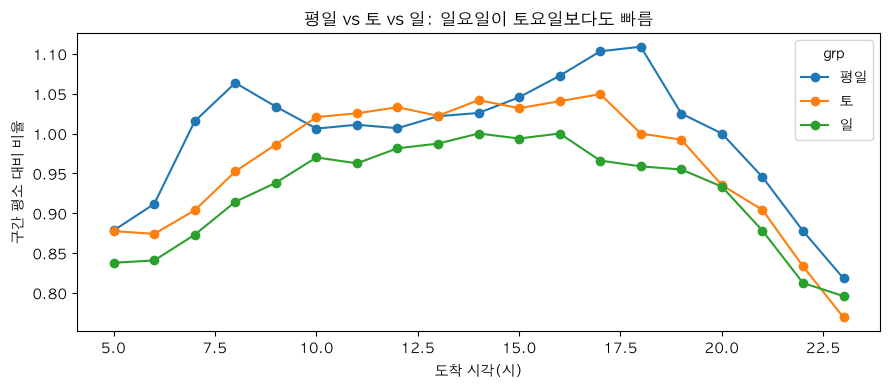

In [26]:
if 'tt_sec' in test.columns:
    E = TEST.assign(p=pred, day=pd.to_datetime(TEST.date).dt.day_of_week.map(DAY))
    E['res'] = E.tt_sec - E.p
    print('요일별 잔차·MAE')
    display(E.groupby('day').agg(행수=('res', 'size'), 잔차중앙값=('res', 'median'), 잔차평균=('res', 'mean'),
                                 길게예측비율=('res', lambda s: (s < 0).mean() * 100), MAE=('res', lambda s: s.abs().mean())).round(2))
    ALL = pd.concat([TRAIN.assign(day=pd.to_datetime(TRAIN.date).dt.day_of_week.map(DAY)), E])
    ALL['grp'] = ALL.day.map(lambda d: d if d in ('토', '일') else '평일')
    ALL['ratio'] = ALL.tt_sec / ALL.groupby('seg_id').tt_sec.transform('median')
    ratio = ALL.pivot_table(index='grp', columns='arrive_hour', values='ratio', aggfunc='median').loc[['평일', '토', '일']]
    print('구간 평소 대비 통행시간 비율 (시간대별 중앙값)')
    display(ratio.round(2))
    ax = ratio.T.plot(figsize=(9, 4), marker='o')
    ax.set_xlabel('도착 시각(시)'); ax.set_ylabel('구간 평소 대비 비율'); ax.set_title('평일 vs 토 vs 일: 일요일이 토요일보다도 빠름')
    plt.tight_layout(); plt.show()

---
# 16. 최종 제출 파일: 일요일 반반 + seed 섞기 (E35 / E36)

14번 모델(E32)에 두 가지를 더함.

1. **일요일 반반 (E35):** 학습에 일요일이 없어서 모델이 일요일을 토요일처럼 예측함. 일요일 행만 두 번 예측해서 평균 냄.
   - 토요일처럼: `is_weekend` = 1, 배차 간격 = 토요일 배차
   - 평일처럼: `is_weekend` = 0, 배차 간격 = 평일 배차
   - 섞는 비율 0.5는 미리 정한 값. 연습 데이터 모의고사(월·화·수·토 학습 → 목·금·일 예측, 대회와 같은 구조)로 확인: 연습 test 27.473 → 27.395
   - 대회 test 정답이나 test 날짜의 실제 값은 쓰지 않음
2. **seed 섞기 (E36):** LightGBM·CatBoost를 seed 0~4로 5번씩 학습해서 같은 모델끼리 평균. 연습 test 27.395 → 27.379

| `N_SEEDS` | 만들어지는 파일 | 대회 public MAE |
|---|---|---|
| 1 | `submissions/{PHASE}_E35_sunmix.csv` | 24.808 |
| 5 | `submissions/{PHASE}_E36_seed5_sunmix.csv` | (제출 안 함) |

seed 0 모델은 14번에서 학습한 것을 그대로 씀. `N_SEEDS = 5`면 대회 데이터 기준 약 6분 더 걸림.

In [ ]:
N_SEEDS = 1        # 1: E35 (일요일 반반) / 5: E36 (seed 5개 + 일요일 반반)
SUN_WD = 0.5       # 일요일: "평일처럼" 예측의 비율 (미리 정한 값)

sun = pd.to_datetime(TEST.date).dt.day_of_week.values == 6
T_SAT = TEST.copy(); T_SAT['is_weekend'] = 1; T_SAT['interval'] = T_SAT.interval_sat      # 토요일처럼
T_WD = TEST.copy();  T_WD['is_weekend'] = 0;  T_WD['interval'] = T_WD.interval_wd         # 평일처럼

t0 = time.time()
P_LGB = {'base': [], 'sat': [], 'wd': []}
P_CB = {'base': [], 'sat': [], 'wd': []}
for seed in range(N_SEEDS):
    if seed == 0:                                   # 14번에서 학습한 seed 0 모델 재사용
        ml, mc = lgb_model, cb_model
    else:
        ml = lgb.LGBMRegressor(**{**FINAL_LGB, 'random_state': seed}).fit(to_X(TRAIN, FINAL_FEATS), TRAIN.tt_sec)
        mc = CatBoostRegressor(**{**FINAL_CB, 'random_seed': seed}, cat_features=['route_id', 'seg_id']).fit(TRAIN[FINAL_FEATS], TRAIN.tt_sec)
    for k, X in [('base', TEST), ('sat', T_SAT), ('wd', T_WD)]:
        P_LGB[k].append(ml.predict(to_X(X, FINAL_FEATS)))
        P_CB[k].append(mc.predict(X[FINAL_FEATS]))
    print(f'seed {seed} 완료 ({time.time() - t0:.0f}초)', flush=True)

blend = lambda k: FINAL_W * np.mean(P_LGB[k], axis=0) + (1 - FINAL_W) * np.mean(P_CB[k], axis=0)
pred_final = np.where(sun, (1 - SUN_WD) * blend('sat') + SUN_WD * blend('wd'), blend('base'))
print(f'일요일 행 {sun.sum():,}개 | 일요일 예측 평균: 그대로 {blend("base")[sun].mean():.1f} → 반반 {pred_final[sun].mean():.1f}')

name = 'E35_sunmix' if N_SEEDS == 1 else f'E36_seed{N_SEEDS}_sunmix'
sub_final = pd.DataFrame({'row_id': TEST.row_id.values, 'tt_sec': np.round(pred_final, 1)})
sub_final = sub_final.set_index('row_id').loc[test.row_id].reset_index()       # 원래 test 순서로
assert len(sub_final) == len(test) and sub_final.tt_sec.notna().all() and not sub_final.row_id.duplicated().any()
path_final = f'../submissions/{PHASE}_{name}.csv'
sub_final.to_csv(path_final, index=False)
print(path_final, sub_final.shape, '| 결측 0 | 중복 0')

if 'tt_sec' in test.columns:                      # 연습용: 정답이 있으므로 채점
    t = test.assign(p=sub_final.tt_sec.values)
    print(f"test MAE {mae(t.tt_sec, t.p):.3f}", {DAY[pd.Timestamp(d).day_of_week]: round(mae(g.tt_sec, g.p), 3) for d, g in t.groupby('date')})

---
# 17. 회차 구간 힌트 추가 (E41)

16번(E35)에 **회차 구간(종점 대기) 힌트 피처 10개**를 더함. 나머지(두 모델, 섞는 비율 0.8, 일요일 반반 0.5)는 E35와 같음.

- **회차 구간:** 노선마다 상행 구간 중 train 중앙값이 가장 긴 구간. 종점에서 쉬는 시간이 들어 있어서 행은 0.67%뿐인데 MAE가 224초 (전체 오차의 약 6%)
- **힌트:** 같은 차량의 **다음 운행(반대 방향)이 몇 시에 시작하는지**, 그 앞뒤 시간에 기록된 행 수 등. 오래 쉬면 다음 운행이 다음 시로 넘어감
  - train 회차 행: 다음 운행이 같은 시 → 중앙값 596초 / 다음 시 → 788초
  - 입력 `arrive_hour`만 씀 (정답 안 씀). 회차 구간 행에만 값을 넣고 나머지 행은 비워 둠
- 회차 구간은 상행 마지막(또는 끝에서 둘째) 구간이라 바로 다음 행은 반대 방향 다음 운행에 있음 → 차량 하루 단위로 찾음

| | 대회 train 검증 예상 | 연습 모의고사 | 대회 public MAE |
|---|---|---|---|
| E35 | 25.402 | 27.395 | 24.808 |
| **E41** | **25.229** | **27.127** | **24.610** |

만들어지는 파일: `submissions/{PHASE}_E41_turnhint_sunmix.csv` (대회 데이터 약 2분)

In [ ]:
# 회차 구간: 노선마다 상행 구간 중 train 중앙값 최대
SEGK = ['route_id', 'direction', 'from_stop', 'to_stop']
med = TRAIN[TRAIN.direction == 0].groupby(SEGK).tt_sec.median().reset_index()
TURN = med.loc[med.groupby('route_id').tt_sec.idxmax(), SEGK].assign(is_turn2=1)

TRIP = ['date', 'vehicle_id', 'route_id', 'direction', 'trip_no']
VD = ['date', 'vehicle_id']          # 차량 하루 (확인: 차량 하루에 노선은 항상 1개)
H = ['t_prev_gap', 't_blk_n', 't_blk_dist', 't_blk_before', 't_blk_after',
     'v_blk_n', 'v_prev_n', 'v_next_n', 'v_next_trip_gap', 'v_next_trip_n0']


def add_turn_hint(df):
    """회차 구간은 상행의 마지막(또는 끝에서 둘째) 구간이라, 바로 뒤 행은 반대 방향 다음 운행에 있음 → 차량 하루 단위로 봄."""
    df = df.merge(TURN, on=SEGK, how='left').set_index(df.index)
    df['is_turn2'] = df.is_turn2.fillna(0).astype(int)
    s = df.sort_values(TRIP + ['stop_seq']).copy()
    s['t_prev_gap'] = s.arrive_hour - s.groupby(TRIP).arrive_hour.shift(1)     # 같은 운행 바로 앞 구간과 시각 차이
    b = s.groupby(TRIP + ['arrive_hour'])
    s['t_blk_n'] = b.stop_seq.transform('size')                                # 이 운행에서 같은 시에 든 구간 수
    s['t_blk_dist'] = b.dist_m.transform('sum')
    s['t_blk_before'] = s.stop_seq - b.stop_seq.transform('min')
    s['t_blk_after'] = b.stop_seq.transform('max') - s.stop_seq
    # 차량 하루 전체에서 시간별 행 수 (방향 상관없이)
    vc = s.groupby(VD + ['arrive_hour']).size()
    def vcount(shift):
        k = pd.MultiIndex.from_arrays([s.date, s.vehicle_id, s.arrive_hour + shift])
        return vc.reindex(k).fillna(0).values
    s['v_blk_n'], s['v_prev_n'], s['v_next_n'] = vcount(0), vcount(-1), vcount(1)
    # 다음 운행: 이 운행이 끝난 시각 이후에 시작하는 같은 차량의 운행 중 가장 이른 것
    tr = s.groupby(TRIP).agg(start=('arrive_hour', 'min'), end=('arrive_hour', 'max'), first_seq=('stop_seq', 'min')).reset_index()
    first_n = s.merge(tr[TRIP + ['start']], on=TRIP).query('arrive_hour == start').groupby(TRIP).size().rename('n0').reset_index()
    tr = tr.merge(first_n, on=TRIP, how='left')
    nxt = []
    for _, g in tr.groupby(VD):
        g = g.sort_values(['start', 'end'])
        for r in g.itertuples():
            c = g[(g.start >= r.end) & ~((g.direction == r.direction) & (g.trip_no == r.trip_no) & (g.route_id == r.route_id))]
            c = c[c.direction != r.direction] if (c.direction != r.direction).any() else c
            nxt.append((r.date, r.vehicle_id, r.route_id, r.direction, r.trip_no,
                        c.start.min() if len(c) else np.nan, c.sort_values('start').n0.iloc[0] if len(c) else np.nan))
    nxt = pd.DataFrame(nxt, columns=TRIP + ['next_start', 'v_next_trip_n0'])
    s = s.merge(nxt, on=TRIP, how='left').set_index(s.index)
    s['v_next_trip_gap'] = s.next_start - s.arrive_hour                         # 다음 운행 시작까지 몇 시간
    s.loc[s.is_turn2 == 0, H] = np.nan                                           # 회차 구간 행에만 값
    return s.loc[df.index]

TR_H, TE_H = add_turn_hint(TRAIN), add_turn_hint(TEST)
print(f'회차 행: train {TR_H.is_turn2.sum():,} | test {TE_H.is_turn2.sum():,} | test 회차 행 중 다음 운행 찾음 {TE_H.loc[TE_H.is_turn2 == 1, "v_next_trip_gap"].notna().mean():.1%}')
E41_FEATS = FINAL_FEATS + H                     # E5 25개 + 회차 힌트 10개

t0 = time.time()
ml41 = lgb.LGBMRegressor(**FINAL_LGB).fit(to_X(TR_H, E41_FEATS), TR_H.tt_sec)
mc41 = CatBoostRegressor(**FINAL_CB, cat_features=['route_id', 'seg_id']).fit(TR_H[E41_FEATS], TR_H.tt_sec)
pred41 = lambda X: FINAL_W * ml41.predict(to_X(X, E41_FEATS)) + (1 - FINAL_W) * mc41.predict(X[E41_FEATS])
sun41 = pd.to_datetime(TE_H.date).dt.day_of_week.values == 6
S41 = TE_H.copy(); S41['is_weekend'] = 1; S41['interval'] = S41.interval_sat     # 토요일처럼
W41 = TE_H.copy(); W41['is_weekend'] = 0; W41['interval'] = W41.interval_wd      # 평일처럼
p41 = np.where(sun41, (1 - SUN_WD) * pred41(S41) + SUN_WD * pred41(W41), pred41(TE_H))
print(f'학습·예측 {time.time() - t0:.0f}초')

sub41 = pd.DataFrame({'row_id': TE_H.row_id.values, 'tt_sec': np.round(p41, 1)}).set_index('row_id').loc[test.row_id].reset_index()
assert len(sub41) == len(test) and sub41.tt_sec.notna().all() and not sub41.row_id.duplicated().any()
path41 = f'../submissions/{PHASE}_E41_turnhint_sunmix.csv'
sub41.to_csv(path41, index=False)
print(path41, sub41.shape, '| 결측 0 | 중복 0')

if 'tt_sec' in test.columns:                      # 연습용: 정답이 있으므로 채점
    t = test.assign(p=sub41.tt_sec.values)
    print(f"test MAE {mae(t.tt_sec, t.p):.3f}", {DAY[pd.Timestamp(d).day_of_week]: round(mae(g.tt_sec, g.p), 3) for d, g in t.groupby('date')})

---
# 18. 최종 제출 파일: 목·금 평일 전용 모델 + 일요일 노선별 섞기 (E46)

17번(E41)에서 두 가지를 바꿈. 둘이 바꾸는 요일이 겹치지 않음.

1. **목·금 (E44):** E41 예측 × 0.5 + **평일 전용 LightGBM** × 0.5
   - 평일 전용 = E41과 같은 피처·설정인데 **월·화·수만 학습** (회차 구간도 월·화·수로 다시 고름)
   - 대회 train 검증 (월←화·수, 화←월·수, 수←월·화): 평일 23.332 → 23.261, 3일 모두 좋아짐
2. **일요일 (E45):** 일요일 배차가 토요일과 다른 노선(2, 704, B1)만 토요일처럼·평일처럼·그대로(일요일 배차) ⅓씩. 배차가 같은 노선(211, 311)은 기존 반반
   - 규칙은 배차 값만 보고 미리 정함 (정답 안 씀)

| | 연습 test | 대회 public MAE |
|---|---|---|
| E41 | 27.127 | 24.610 |
| **E46** | **27.039** | **24.577** |

만들어지는 파일: `submissions/{PHASE}_E46_wd_route_sunmix.csv` (17번 다음에 실행, 약 1분 더)

In [ ]:
WDAY = pd.to_datetime(TRAIN.date).dt.day_of_week.values < 5
TR_WD = TRAIN[WDAY]                                              # 월·화·수
med_wd = TR_WD[TR_WD.direction == 0].groupby(SEGK).tt_sec.median().reset_index()
TURN_WD = med_wd.loc[med_wd.groupby('route_id').tt_sec.idxmax(), SEGK].assign(is_turn2=1)   # 회차 구간 (평일만으로)

def hint_with(df, turn):
    """17번 add_turn_hint를 다른 회차 구간 목록으로 실행"""
    global TURN
    keep = TURN; TURN = turn
    try:
        return add_turn_hint(df)
    finally:
        TURN = keep

t0 = time.time()
F_WD, T_WD = hint_with(TR_WD, TURN_WD), hint_with(TEST, TURN_WD)
p_wd = lgb.LGBMRegressor(**FINAL_LGB).fit(to_X(F_WD, E41_FEATS), F_WD.tt_sec).predict(to_X(T_WD, E41_FEATS))
print(f'평일 전용 LightGBM 학습·예측 {time.time() - t0:.0f}초')

# 1) 목·금 (E44): E41 제출값 × 0.5 + 평일 전용 × 0.5
e41_val = sub41.set_index('row_id').tt_sec.loc[TEST.row_id.values].values
is_sun = pd.to_datetime(TEST.date).dt.day_of_week.values == 6
p44 = np.round(np.where(~is_sun, 0.5 * e41_val + 0.5 * p_wd, e41_val), 1)

# 2) 일요일 (E45): 배차가 토요일과 다른 노선만 토요일처럼·평일처럼·그대로 1/3씩
pS, pW, pB = pred41(S41), pred41(W41), pred41(TE_H)
diff_int = (TE_H.interval_sun != TE_H.interval_sat).values
p45 = np.round(np.where(sun41, np.where(diff_int, (pS + pW + pB) / 3, 0.5 * pS + 0.5 * pW), pB), 1)
print('일요일 배차 ≠ 토요일 노선:', sorted(TE_H.route_nm[diff_int & sun41].unique()))

# 3) 합치기 (E46): 목·금 = E44, 일 = E45
assert (TE_H.row_id.values == TEST.row_id.values).all()
p46 = np.where(is_sun, p45, p44)
sub46 = pd.DataFrame({'row_id': TEST.row_id.values, 'tt_sec': p46}).set_index('row_id').loc[test.row_id].reset_index()
assert len(sub46) == len(test) and sub46.tt_sec.notna().all() and not sub46.row_id.duplicated().any()
path46 = f'../submissions/{PHASE}_E46_wd_route_sunmix.csv'
sub46.to_csv(path46, index=False)
print(path46, sub46.shape, '| 결측 0 | 중복 0 | 음수', int((sub46.tt_sec < 0).sum()))

if 'tt_sec' in test.columns:                      # 연습용: 정답이 있으므로 채점
    t = test.assign(p=sub46.tt_sec.values)
    print(f"test MAE {mae(t.tt_sec, t.p):.3f}", {DAY[pd.Timestamp(d).day_of_week]: round(mae(g.tt_sec, g.p), 3) for d, g in t.groupby('date')})

---
# 19. 회차 구간 시간 추정 피처 추가 (E56)

18번(E46)의 세 모델(기본 LightGBM·CatBoost, 평일 전용 LightGBM) 모두에 피처 1개 추가. 나머지는 E46과 같음.

- **추정 회차 시간** = 3574초 − (같은 날·같은 차량이 같은 시간대에 지나간 **다른** 구간들의 평소 시간 합)
  - 한 버스가 한 시간 동안 지나간 구간 시간을 다 더하면 거의 1시간 (train 중앙값 3,574초)
  - 평소 시간 = 구간 중앙값. 예측할 행은 학습 행 전체로, 학습 행은 **자기 날짜를 뺀 다른 날짜**로 계산 (정답 누출 없음)
  - 회차 구간 행이면서 그 차량의 앞·뒤 시간대 기록이 다 있을 때만 값, 나머지는 결측
- 대회 train 검증: 기본 모델 예상 25.229 → 25.175, 목·금 방식 평일 23.260 → 23.235
- 대회 public: 24.577 → **24.555**

만들어지는 파일: `submissions/{PHASE}_E56_E46_turnest.csv`

In [ ]:
C_EST = 3574.0
VEH = ['date', 'vehicle_id']

def turn_of(fit):
    """학습 행만으로 회차 구간: 노선마다 상행 구간 중 중앙값 최대"""
    med = fit[fit.direction == 0].groupby(SEGK).tt_sec.median().reset_index()
    return med.loc[med.groupby('route_id').tt_sec.idxmax(), SEGK].assign(is_turn2=1)

def seg_med(src, apply):
    md = src.groupby(SEGK).tt_sec.median()
    return apply[SEGK].join(md.rename('x'), on=SEGK).x.values

def add_est(df, med):
    df = df.copy(); df['_m'] = med
    hs = df.groupby(VEH + ['arrive_hour'])._m.sum()
    k = lambda s: pd.MultiIndex.from_arrays([df.date, df.vehicle_id, df.arrive_hour + s])
    inner = k(-1).isin(hs.index) & k(1).isin(hs.index)                 # 그 차량의 앞·뒤 시간대 기록이 다 있음
    others = hs.reindex(k(0)).values - np.nan_to_num(df._m.values)     # 같은 시간대 다른 구간들의 평소 시간 합
    df['turn_est'] = np.where((df.is_turn2 == 1) & inner, C_EST - others, np.nan)
    return df.drop(columns='_m')

def prep_est(fit_raw, apply_raw):
    turn = turn_of(fit_raw)
    f, a = hint_with(fit_raw, turn), hint_with(apply_raw, turn)
    mf = np.full(len(f), np.nan)
    for dd in f.date.unique():                                         # 학습 행: 자기 날짜를 뺀 다른 날짜로
        m = (f.date == dd).values; mf[m] = seg_med(f[~m], f[m])
    return add_est(f, mf), add_est(a, seg_med(f, a))

E56_FEATS = E41_FEATS + ['turn_est']
t0 = time.time()
f56, a56 = prep_est(TRAIN, TEST)
ml56 = lgb.LGBMRegressor(**FINAL_LGB).fit(to_X(f56, E56_FEATS), f56.tt_sec)
mc56 = CatBoostRegressor(**FINAL_CB, cat_features=['route_id', 'seg_id']).fit(f56[E56_FEATS], f56.tt_sec)
pred56 = lambda X: FINAL_W * ml56.predict(to_X(X, E56_FEATS)) + (1 - FINAL_W) * mc56.predict(X[E56_FEATS])
S56 = a56.copy(); S56['is_weekend'] = 1; S56['interval'] = S56.interval_sat
W56 = a56.copy(); W56['is_weekend'] = 0; W56['interval'] = W56.interval_wd
pB56, pS56, pW56 = pred56(a56), pred56(S56), pred56(W56)
sun56 = pd.to_datetime(a56.date).dt.day_of_week.values == 6
diff56 = (a56.interval_sun != a56.interval_sat).values
psun56 = np.where(diff56, (pS56 + pW56 + pB56) / 3, 0.5 * pS56 + 0.5 * pW56)   # 일요일: 18번과 같은 노선별 규칙
fw56, aw56 = prep_est(TRAIN[WDAY], TEST)                                         # 평일 전용
pwd56 = lgb.LGBMRegressor(**FINAL_LGB).fit(to_X(fw56, E56_FEATS), fw56.tt_sec).predict(to_X(aw56, E56_FEATS))
p56 = np.round(np.where(sun56, psun56, 0.5 * pB56 + 0.5 * pwd56), 1)
print(f'학습·예측 {time.time() - t0:.0f}초 | test 회차 행 중 추정값 있음 {a56.turn_est.notna().sum()}/{(a56.is_turn2 == 1).sum()}')

sub56 = pd.DataFrame({'row_id': a56.row_id.values, 'tt_sec': p56}).set_index('row_id').loc[test.row_id].reset_index()
assert len(sub56) == len(test) and sub56.tt_sec.notna().all() and not sub56.row_id.duplicated().any()
path56 = f'../submissions/{PHASE}_E56_E46_turnest.csv'
sub56.to_csv(path56, index=False)
print(path56, sub56.shape, '| 결측 0 | 중복 0 | 음수', int((sub56.tt_sec < 0).sum()))
if 'tt_sec' in test.columns:
    t = test.assign(p=sub56.tt_sec.values)
    print(f"test MAE {mae(t.tt_sec, t.p):.3f}", {DAY[pd.Timestamp(d).day_of_week]: round(mae(g.tt_sec, g.p), 3) for d, g in t.groupby('date')})

---
# 20. 최종 제출 파일: 일요일을 연습 데이터로 학습 (E58) ← 지금 최고

**문제:** 대회 학습 데이터에는 일요일이 없어서 지금까지 일요일은 "토요일처럼"·"평일처럼" 예측을 섞어 추측했음. 연습 데이터로 보면 일요일 오차가 평일보다 3.5초 큼.

**해결:** 연습 데이터(연습 train + 정답이 있는 연습 test, **진짜 일요일 22,376행 포함**)를 학습에 추가하고 `is_sunday` 피처를 넣은 LightGBM으로 **일요일 행만** 예측. 목·금은 19번(E56) 그대로.
- 규칙: `EVALUATION.md` 5. "외부 데이터: 사용하지 않음. **수업에서 제공한 데이터(연습용·대회 데이터)만 씀.**" 대회 test 정답은 쓰지 않음.
- 연습 test 일요일과 대회 test 일요일은 같은 날(2024-09-29)이지만 노선이 다름.
- 검증 (연습 노선 하나를 빼고 나머지로 학습 → 빠진 노선 맞히기, 4번): 일요일 29.459 → 27.577 (4개 노선 모두 1.7~2.1초 좋아짐). 목·금은 오히려 나빠져서(26.112 → 26.407) 일요일에만 씀.
- 대회 public: 24.555 → **24.309**

연습 데이터 피처는 이 노트북의 피처 셀(2, 4, 6, 8, 10, 27, 29, 41번)을 `PHASE = 'practice'`로 한 번 더 실행해서 만듦. `PHASE = 'final'`일 때만 실행됨.

만들어지는 파일: `submissions/final_E58_sunday_practice.csv`

In [ ]:
if PHASE == 'final':
    import json, re
    _nb = json.load(open('cv_feature_experiments.ipynb'))
    GP = {}
    for i in [2, 4, 6, 8, 10, 27, 29, 41]:                          # 같은 피처 셀을 연습 데이터로 실행
        src = ''.join(_nb['cells'][i]['source'])
        if i == 2:
            src = re.sub(r"PHASE = '\w+'", "PHASE = 'practice'", src, count=1)
        exec(src, GP)
    assert GP['PHASE'] == 'practice'

    def prep_sun(tr_raw, te_raw):
        turn = turn_of(tr_raw)
        tr, te = hint_with(tr_raw, turn), hint_with(te_raw, turn)
        for d in (tr, te):
            d['is_sunday'] = (pd.to_datetime(d.date).dt.day_of_week.values == 6).astype(int)
        return tr, te

    PTR, PTE = prep_sun(GP['TRAIN'], GP['TEST'])                     # 연습 train, 연습 test (정답 있음)
    FTR, FTE = prep_sun(TRAIN, TEST)                                 # 대회 train, 대회 test
    E58_FEATS = E41_FEATS + ['is_sunday']
    CATS58 = {c: pd.CategoricalDtype(sorted(pd.concat([PTR[c], PTE[c], FTR[c], FTE[c]]).unique())) for c in ['route_id', 'seg_id']}
    def X58(df):
        x = df[E58_FEATS].copy()
        for c in CATS58: x[c] = x[c].astype(CATS58[c])
        return x
    print(f'학습 행: 대회 train {len(FTR):,} + 연습 train {len(PTR):,} + 연습 test {len(PTE):,} (일요일 {PTE.is_sunday.sum():,})')

    t0 = time.time()
    ALL = pd.concat([FTR, PTR, PTE])
    m58 = lgb.LGBMRegressor(**FINAL_LGB).fit(X58(ALL), ALL.tt_sec)
    sun58 = FTE.is_sunday.values == 1
    p_sun58 = m58.predict(X58(FTE[sun58]))
    print(f'학습·예측 {time.time() - t0:.0f}초 | 대회 test 일요일 {sun58.sum():,}행')

    e56s = sub56.set_index('row_id').tt_sec
    new58 = e56s.copy()
    new58.loc[FTE.row_id.values[sun58]] = np.round(p_sun58, 1)      # 일요일만 바꿈, 목·금은 19번(E56) 그대로
    sub58 = new58.loc[test.row_id].reset_index()
    sub58.columns = ['row_id', 'tt_sec']
    assert len(sub58) == len(test) and sub58.tt_sec.notna().all() and not sub58.row_id.duplicated().any() and (sub58.tt_sec >= 0).all()
    path58 = '../submissions/final_E58_sunday_practice.csv'
    sub58.to_csv(path58, index=False)
    d = sub58.set_index('row_id').tt_sec.loc[FTE.row_id.values[sun58]].values - e56s.loc[FTE.row_id.values[sun58]].values
    print(path58, sub58.shape, f'| 결측·중복·음수 0 | 일요일 E56 대비 평균 {d.mean():+.2f}초')
else:
    print('20번은 대회 데이터(PHASE = final)에서만 실행함 (연습 데이터를 학습에 추가하는 단계)')